# Lab 2 — Music Genre Classification with CNNs

Notebook didáctico para clasificar géneros musicales a partir de mel-spectrograms. Incluye una CNN sencilla y un modelo VGG16 preentrenado. No modifica ningún archivo de `Lab1`.

**Datos esperados:** la carpeta `images_original` del dataset GTZAN, con una subcarpeta por género. En Colab puedes montar Drive o subir la carpeta; en Jupyter, indica su ruta en la siguiente sección.

## 1. Imports y configuración

Si falta alguna librería, descomenta y ejecuta la instalación. TensorFlow/Keras es la librería usada en este notebook.

In [1]:
# %pip install tensorflow scikit-learn matplotlib
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)

I0000 00:00:1792969216.821292   22977 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792969216.821936   22977 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792969216.870396   22977 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792969217.972392   22977 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

TensorFlow: 2.22.0-rc0


## 2. Cargar las imágenes

Cambia `DATA_DIR` para que apunte a `images_original`. Se separan las rutas de forma estratificada: 80% para desarrollo y 20% para test. La validación se extrae únicamente del conjunto de desarrollo.

In [2]:
# Ejemplo Colab: '/content/drive/MyDrive/GTZAN/images_original'
DATA_DIR = 'Data/images_original'  # Cambia esta ruta según dónde estén los datos
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f'No encuentro {DATA_DIR}. Cambia DATA_DIR para apuntar a images_original.')

class_names = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
extensions = ('.png', '.jpg', '.jpeg', '.bmp')
paths, labels = [], []
for label, genre in enumerate(class_names):
    folder = os.path.join(DATA_DIR, genre)
    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith(extensions):
            paths.append(os.path.join(folder, filename))
            labels.append(label)

paths = np.array(paths)
labels = np.array(labels)
print('Géneros:', class_names)
print('Total de imágenes:', len(paths))
if len(paths) == 0:
    raise ValueError('No se han encontrado imágenes. Comprueba la estructura de carpetas.')

train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths, labels, test_size=0.20, random_state=SEED, stratify=labels
)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels, test_size=0.20, random_state=SEED, stratify=train_labels
)
print(f'Train: {len(train_paths)} | Validation: {len(val_paths)} | Test: {len(test_paths)}')

Géneros: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Total de imágenes: 999
Train: 639 | Validation: 160 | Test: 200


E0000 00:00:1792969219.867003   22977 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1792969219.867460   23935 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1792969219.901872   22977 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory
W0000 00:00:1792969219.901891   22

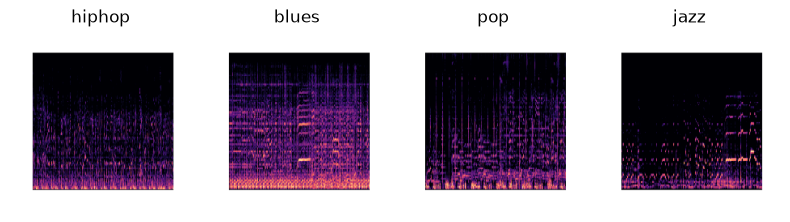

In [3]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

for images, labels_batch in train_ds.take(1):
    plt.figure(figsize=(8, 4))
    for i in range(min(4, len(images))):
        plt.subplot(1, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8))
        plt.title(class_names[int(labels_batch[i])])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## 3. Task 1 — CNN sencilla

Entrenamos la CNN definida en `generate_model()`, siguiendo la arquitectura de referencia: dos capas convolucionales, dos capas de max pooling, una capa densa de 1024 neuronas y una salida con una neurona por género. Se usa EarlyStopping para limitar el entrenamiento cuando la validación deja de mejorar.

In [4]:
# Keras usa el nombre `kernel_size` en Conv2D. Este adaptador permite
# conservar `filter_size` tal como aparece en la referencia del laboratorio.
class Conv2DWithFilterSize(tf.keras.layers.Conv2D):
    def __init__(self, filters, filter_size, **kwargs):
        super().__init__(filters=filters, kernel_size=filter_size, **kwargs)


def generate_model(num_classes):
    model = tf.keras.Sequential([
        # Resize first to keep the Flatten + Dense(1024) classifier manageable.
        tf.keras.layers.Resizing(64, 64, input_shape=(224, 224, 3)),
        tf.keras.layers.Rescaling(1./255),

        # first convolutional layer
        Conv2DWithFilterSize(32, filter_size=3, activation='relu'),
        tf.keras.layers.MaxPool2D(pool_size=2, strides=2),

        # second convolutional layer
        Conv2DWithFilterSize(64, filter_size=3, activation='relu'),
        tf.keras.layers.MaxPool2D(pool_size=2, strides=2),

        # fully connected classifier
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(1024, activation='relu'),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


num_classes = len(class_names)
model = generate_model(num_classes)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=2, restore_best_weights=True
        )
    ]
)

best_cnn = {
    'filters': (32, 64),
    'val_accuracy': max(history.history['val_accuracy']),
    'model': model,
    'history': history
}
cnn_test_loss, cnn_test_accuracy = model.evaluate(test_ds, verbose=0)
print('CNN — validation accuracy:', round(best_cnn['val_accuracy'], 4))
print(f'CNN — test accuracy: {cnn_test_accuracy:.4f}')

Epoch 1/8


/home/lucialinux/MLSM-labs/.venv/lib/python3.14/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/home/lucialinux/MLSM-labs/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 287ms/step - accuracy: 0.1471 - loss: 2.3431 - val_accuracy: 0.2438 - val_loss: 2.1515
Epoch 2/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 207ms/step - accuracy: 0.2817 - loss: 1.9888 - val_accuracy: 0.4187 - val_loss: 1.7368
Epoch 3/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - accuracy: 0.4178 - loss: 1.7004 - val_accuracy: 0.4250 - val_loss: 1.6304
Epoch 4/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - accuracy: 0.5321 - loss: 1.4359 - val_accuracy: 0.5562 - val_loss: 1.3700
Epoch 5/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - accuracy: 0.5509 - loss: 1.2243 - val_accuracy: 0.4688 - val_loss: 1.4258
Epoch 6/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - accuracy: 0.6698 - loss: 1.0337 - val_accuracy: 0.5188 - val_loss: 1.3713
CNN — validation accuracy: 0.5562
CNN — test accuracy: 0.4950


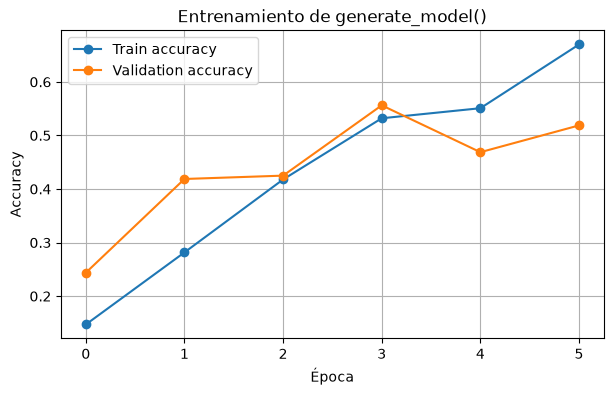

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['accuracy'], marker='o', label='Train accuracy')
plt.plot(history.history['val_accuracy'], marker='o', label='Validation accuracy')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title('Entrenamiento de generate_model()')
plt.legend()
plt.grid(True)
plt.show()

## 4. Task 2 — VGG16 preentrenada

Usamos VGG16 con pesos de ImageNet como extractor de características congelado y entrenamos una cabeza de clasificación. Es una adaptación sencilla de un modelo de visión a imágenes de espectrogramas.

In [6]:
base = tf.keras.applications.VGG16(
    weights='imagenet', include_top=False, input_shape=(224, 224, 3)
)
base.trainable = False


In [7]:
inputs = tf.keras.Input(shape=(224, 224, 3))

# Augmentation: the input is still in the 0–255 range.
x = tf.keras.layers.RandomTranslation(0.05, 0.05)(inputs)
x = tf.keras.layers.RandomZoom(0.1)(x)
x = tf.keras.layers.RandomContrast(0.1)(x)

x = tf.keras.applications.vgg16.preprocess_input(x)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(1e-4)
)(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(
    num_classes, activation="softmax"
)(x)

vgg_model = tf.keras.Model(inputs, outputs)

In [8]:
vgg_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
vgg_history = vgg_model.fit(
    train_ds, validation_data=val_ds, epochs=5,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True)]
)
vgg_test_loss, vgg_test_accuracy = vgg_model.evaluate(test_ds, verbose=0)
print(f'VGG16 — test accuracy: {vgg_test_accuracy:.4f}')

Epoch 1/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 90s 4s/step - accuracy: 0.0892 - loss: 6.7669 - val_accuracy: 0.0688 - val_loss: 5.3746
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 85s 4s/step - accuracy: 0.0939 - loss: 3.8343 - val_accuracy: 0.0750 - val_loss: 3.3923
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 96s 5s/step - accuracy: 0.1565 - loss: 2.8232 - val_accuracy: 0.2188 - val_loss: 2.6191
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 91s 5s/step - accuracy: 0.2300 - loss: 2.4180 - val_accuracy: 0.2937 - val_loss: 2.2807
Epoch 5/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 85s 4s/step - accuracy: 0.2817 - loss: 2.1459 - val_accuracy: 0.3438 - val_loss: 2.0735
VGG16 — test accuracy: 0.3250


## 5. Resultados y comparación

La accuracy de test es la métrica principal para comparar modelos, porque ambos se evalúan sobre las mismas imágenes reservadas. No se incluyen resultados inventados: los valores aparecen al ejecutar el notebook.

Modelo                   Configuración                      Test accuracy
------------------------------------------------------------------------------
CNN generate_model()     Conv2D (32, 64) + Dense(1024)      0.4950
VGG16 congelada          ImageNet + cabeza densa            0.3250

Informe de clasificación para la CNN generate_model():
              precision    recall  f1-score   support

       blues       0.43      0.30      0.35        20
   classical       0.88      0.70      0.78        20
     country       0.64      0.45      0.53        20
       disco       0.30      0.70      0.42        20
      hiphop       0.28      0.80      0.42        20
        jazz       0.78      0.70      0.74        20
       metal       0.83      0.50      0.62        20
         pop       1.00      0.45      0.62        20
      reggae       1.00      0.05      0.10        20
        rock       0.50      0.30      0.38        20

    accuracy                           0.49       200
   macr

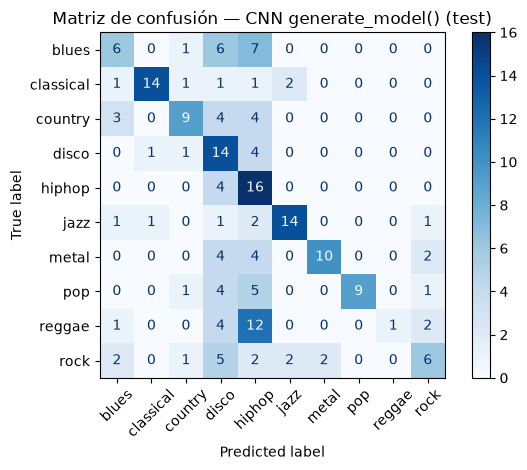

In [9]:
results = [
    ('CNN generate_model()', 'Conv2D (32, 64) + Dense(1024)', float(cnn_test_accuracy)),
    ('VGG16 congelada', 'ImageNet + cabeza densa', float(vgg_test_accuracy)),
]
print(f'{"Modelo":<24} {"Configuración":<34} Test accuracy')
print('-' * 78)
for name, config, accuracy in results:
    print(f'{name:<24} {config:<34} {accuracy:.4f}')

y_true = test_labels
y_pred = np.argmax(best_cnn['model'].predict(test_ds, verbose=0), axis=1)
print('\nInforme de clasificación para la CNN generate_model():')
print(classification_report(y_true, y_pred, labels=range(num_classes), target_names=class_names, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=range(num_classes)), display_labels=class_names).plot(xticks_rotation=45, cmap='Blues')
plt.title('Matriz de confusión — CNN generate_model() (test)')
plt.tight_layout()
plt.show()

## 6. Discusión y comparación con Lab 1

Completa esta sección después de ejecutar el notebook. Compara la accuracy de test de la CNN definida por `generate_model()` y VGG16 con los resultados de Lab 1 obtenidos usando descriptores extraídos manualmente. Asegúrate de comparar métricas calculadas sobre particiones equivalentes; si las particiones o los datos no coinciden, indícalo. Comenta brevemente el coste de entrenamiento y los posibles errores de clasificación.

## Conclusión

Este laboratorio permite comparar la CNN de la función `generate_model()`, entrenada desde cero, con una VGG16 preentrenada usando mel-spectrograms como imágenes. La conclusión final debe basarse en las accuracies y matrices de confusión obtenidas al ejecutar las celdas.

## Notas de ejecución

1. Descarga o monta la carpeta `images_original` del enlace de datos proporcionado en el guion.
2. Ajusta `DATA_DIR` en la sección 2.
3. Ejecuta las celdas en orden. En Colab se recomienda activar un runtime con GPU para VGG16.
4. Las primeras ejecuciones descargan los pesos de VGG16 de ImageNet si no están disponibles localmente.

**Nota metodológica:** los espectrogramas del mismo tema musical podrían estar relacionados si el dataset contiene varias imágenes por canción. Para evitar fugas de información, lo ideal es dividir por canción original si se conoce esa correspondencia. Esta versión usa una división estratificada aleatoria por imagen para mantener el ejercicio simple.